<a href="https://colab.research.google.com/github/Megan-28/fake-news-detection-bert/blob/main/fake_news_bert.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import torch
import transformers
import accelerate

print("Torch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("Accelerate:", accelerate.__version__)

from transformers import Trainer, TrainingArguments

print("Everything working!")


A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.0.2 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "/usr/local/lib/python3.12/dist-packages/colab_kernel_launcher.py", line 37, in <module>
    ColabKernelApp.launch_instance()
  File "/usr/local/lib/python3.12/dist-packages/traitlets/config/application.py", line 992, in launch_instance
    app.start()
  File "/usr/local/lib/python3.12/dist-packages/ipykernel/kernelapp.py", line 712, in start
    self.io_loop.start()
  File "/usr/local/lib/python3.12/dist-package

Torch: 2.2.2+cu121
Transformers: 4.40.2
Accelerate: 0.29.3
Everything working!


In [ ]:
from google.colab import files
files.upload()

Saving kaggle.json to kaggle (2).json


{'kaggle (2).json': b'{"username":"angelinaruth","key":"620df1c8367260d2ae047101fb81537e"}'}

In [ ]:
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

In [ ]:
!kaggle datasets download -d clmentbisaillon/fake-and-real-news-dataset

Dataset URL: https://www.kaggle.com/datasets/clmentbisaillon/fake-and-real-news-dataset
License(s): CC-BY-NC-SA-4.0
fake-and-real-news-dataset.zip: Skipping, found more recently modified local copy (use --force to force download)


In [ ]:
!unzip -q fake-and-real-news-dataset.zip

replace Fake.csv? [y]es, [n]o, [A]ll, [N]one, [r]ename: A


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    auc
)

import torch

from transformers import (
    BertTokenizer,
    BertForSequenceClassification,
    Trainer,
    TrainingArguments
)

from datasets import Dataset

In [ ]:
fake_df = pd.read_csv("Fake.csv")
true_df = pd.read_csv("True.csv")

fake_df["label"] = 0
true_df["label"] = 1

df = pd.concat([fake_df, true_df], axis=0)

df = df.sample(frac=1, random_state=42).reset_index(drop=True)

print(df.shape)

df.head()

(44898, 5)


,title,text,subject,date,label
0,Ben Stein Calls Out 9th Circuit Court: Committ...,"21st Century Wire says Ben Stein, reputable pr...",US_News,"February 13, 2017",0
1,Trump drops Steve Bannon from National Securit...,WASHINGTON (Reuters) - U.S. President Donald T...,politicsNews,"April 5, 2017",1
2,Puerto Rico expects U.S. to lift Jones Act shi...,(Reuters) - Puerto Rico Governor Ricardo Rosse...,politicsNews,"September 27, 2017",1
3,OOPS: Trump Just Accidentally Confirmed He Le...,"On Monday, Donald Trump once again embarrassed...",News,"May 22, 2017",0
4,Donald Trump heads for Scotland to reopen a go...,"GLASGOW, Scotland (Reuters) - Most U.S. presid...",politicsNews,"June 24, 2016",1


In [ ]:
fake_df = pd.read_csv("Fake.csv")     #Load dataset
true_df = pd.read_csv("True.csv")

fake_df["label"] = 0
true_df["label"] = 1

df = pd.concat([fake_df, true_df], axis=0)

df = df.sample(frac=1, random_state=42).reset_index(drop=True)

print(df.columns)

Index(['title', 'text', 'subject', 'date', 'label'], dtype='object')


In [ ]:
df["content"] = df["text"]          #Data Preprocessing

df = df[["content", "label"]]

df.dropna(inplace=True)

df.head()

,content,label
0,"21st Century Wire says Ben Stein, reputable pr...",0
1,WASHINGTON (Reuters) - U.S. President Donald T...,1
2,(Reuters) - Puerto Rico Governor Ricardo Rosse...,1
3,"On Monday, Donald Trump once again embarrassed...",0
4,"GLASGOW, Scotland (Reuters) - Most U.S. presid...",1


In [ ]:
# Train/Test Split
df_small = df.sample(frac=0.35, random_state=42)

train_texts, test_texts, train_labels, test_labels = train_test_split(
    df_small["content"],
    df_small["label"],
    test_size=0.2,
    random_state=42,
    stratify=df_small["label"]
)

train_texts, val_texts, train_labels, val_labels = train_test_split(
    train_texts,
    train_labels,
    test_size=0.1,
    random_state=42
)

print("Train:", len(train_texts))
print("Validation:", len(val_texts))
print("Test:", len(test_texts))

Train: 11313
Validation: 1258
Test: 3143


In [ ]:
tokenizer = BertTokenizer.from_pretrained("bert-base-uncased")

/usr/local/lib/python3.12/dist-packages/huggingface_hub/file_download.py:949: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(


In [ ]:
print("Tokenizer loaded successfully!")

Tokenizer loaded successfully!


In [ ]:
def tokenize(batch):                    #Tokenization
    return tokenizer(
        batch["content"],
        padding="max_length",
        truncation=True,
        max_length=128
    )

train_dataset = Dataset.from_dict({
    "content": train_texts.tolist(),
    "label": train_labels.tolist()
})

val_dataset = Dataset.from_dict({
    "content": val_texts.tolist(),
    "label": val_labels.tolist()
})

test_dataset = Dataset.from_dict({
    "content": test_texts.tolist(),
    "label": test_labels.tolist()
})

train_dataset = train_dataset.map(tokenize, batched=True)
val_dataset = val_dataset.map(tokenize, batched=True)
test_dataset = test_dataset.map(tokenize, batched=True)

train_dataset.set_format(
    type="torch",
    columns=["input_ids", "attention_mask", "label"]
)

val_dataset.set_format(
    type="torch",
    columns=["input_ids", "attention_mask", "label"]
)

test_dataset.set_format(
    type="torch",
    columns=["input_ids", "attention_mask", "label"]
)

Map:   0%|          | 0/11313 [00:00<?, ? examples/s]

Map:   0%|          | 0/1258 [00:00<?, ? examples/s]

Map:   0%|          | 0/3143 [00:00<?, ? examples/s]

In [ ]:
model = BertForSequenceClassification.from_pretrained(          #Load BERT Model
    "bert-base-uncased",
    num_labels=2
)

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at bert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


In [ ]:
training_args = TrainingArguments(
    output_dir="./results",                                   #Training Setup
    evaluation_strategy="epoch",
    save_strategy="epoch",
    learning_rate=2e-5,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,
    num_train_epochs=2,
    weight_decay=0.01,
    logging_dir="./logs",
    load_best_model_at_end=True,
    report_to="none"
)

In [ ]:
def compute_metrics(pred):

    labels = pred.label_ids
    preds = pred.predictions.argmax(-1)

    accuracy = accuracy_score(labels, preds)
    precision = precision_score(labels, preds)
    recall = recall_score(labels, preds)
    f1 = f1_score(labels, preds)

    return {
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1
    }

In [ ]:
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    compute_metrics=compute_metrics
)

trainer.train()

Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,0.004300,0.005088,0.998410,0.998384,0.998384,0.998384
2,0.004800,0.005800,0.999205,1.000000,0.998384,0.999192


TrainOutput(global_step=2830, training_loss=0.008512167040877334, metrics={'train_runtime': 784.6936, 'train_samples_per_second': 28.834, 'train_steps_per_second': 3.607, 'total_flos': 1488287684643840.0, 'train_loss': 0.008512167040877334, 'epoch': 2.0})

In [ ]:
predictions = trainer.predict(test_dataset)

pred_probs = predictions.predictions
pred_labels = np.argmax(pred_probs, axis=1)

accuracy = accuracy_score(test_labels, pred_labels)
precision = precision_score(test_labels, pred_labels)
recall = recall_score(test_labels, pred_labels)
f1 = f1_score(test_labels, pred_labels)

print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)

Accuracy: 0.9977728285077951
Precision: 0.9966688874083944
Recall: 0.9986648865153538
F1 Score: 0.9976658886295432


In [ ]:
print(classification_report(test_labels, pred_labels))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00      1645
           1       1.00      1.00      1.00      1498

    accuracy                           1.00      3143
   macro avg       1.00      1.00      1.00      3143
weighted avg       1.00      1.00      1.00      3143



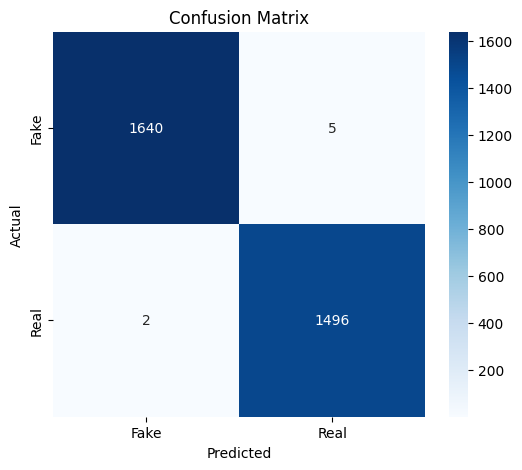

In [ ]:
cm = confusion_matrix(test_labels, pred_labels)

plt.figure(figsize=(6,5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Fake', 'Real'],
    yticklabels=['Fake', 'Real']
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

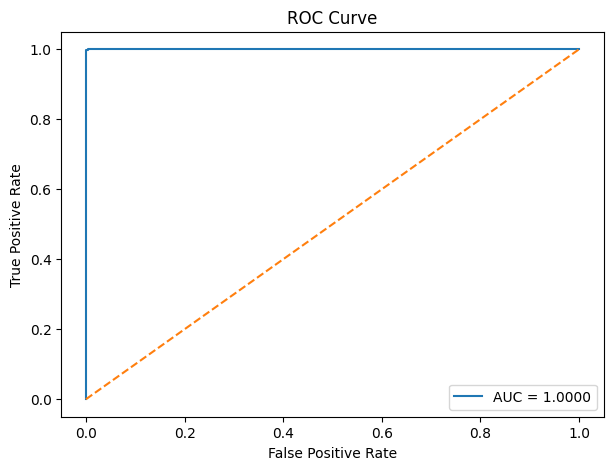

AUC Score: 0.9999699700918347


In [ ]:
fake_probs = torch.nn.functional.softmax(
    torch.tensor(pred_probs),
    dim=1
)[:,1].numpy()

fpr, tpr, thresholds = roc_curve(
    test_labels,
    fake_probs
)

roc_auc = auc(fpr, tpr)

plt.figure(figsize=(7,5))

plt.plot(
    fpr,
    tpr,
    label=f"AUC = {roc_auc:.4f}"
)

plt.plot([0,1], [0,1], linestyle='--')

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()

print("AUC Score:", roc_auc)

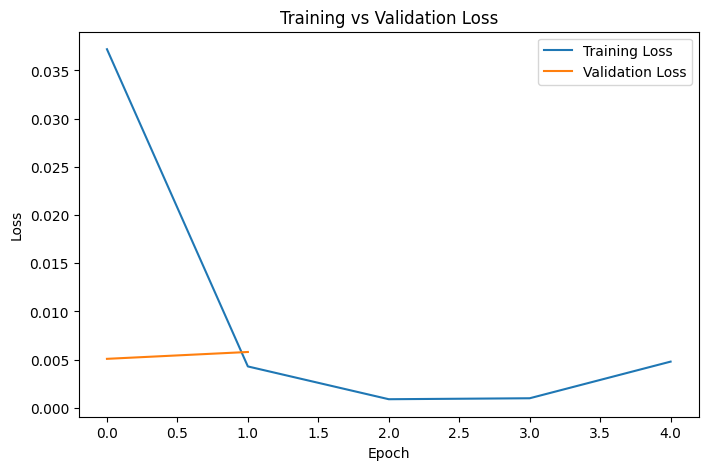

In [ ]:
logs = trainer.state.log_history

train_loss = []
eval_loss = []

for log in logs:
    if "loss" in log:
        train_loss.append(log["loss"])

    if "eval_loss" in log:
        eval_loss.append(log["eval_loss"])

plt.figure(figsize=(8,5))

plt.plot(train_loss, label="Training Loss")
plt.plot(eval_loss, label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.show()

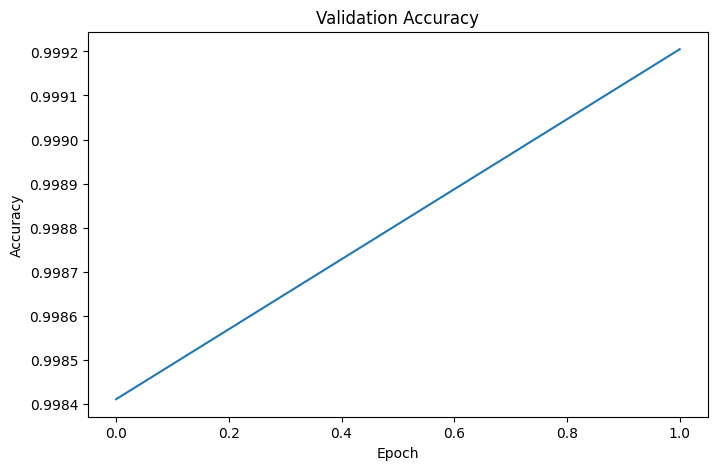

In [ ]:
eval_accuracy = []

for log in logs:
    if "eval_accuracy" in log:
        eval_accuracy.append(log["eval_accuracy"])

plt.figure(figsize=(8,5))

plt.plot(eval_accuracy)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Validation Accuracy")
plt.show()

In [ ]:
def predict_news(news_text):

    inputs = tokenizer(
        news_text,
        return_tensors="pt",
        truncation=True,
        padding=True,
        max_length=128
    )

    device = torch.device(
        "cuda" if torch.cuda.is_available() else "cpu"
    )

    model.to(device)

    inputs = {
        key: value.to(device)
        for key, value in inputs.items()
    }

    with torch.no_grad():
        outputs = model(**inputs)

    prediction = torch.argmax(
        outputs.logits,
        dim=1
    ).item()

    return "Real News" if prediction == 1 else "Fake News"

In [ ]:
news = "Scientists discover a new planet that can support life"

print(predict_news(news))

Fake News


In [ ]:
model.save_pretrained("fake_news_bert_model")
tokenizer.save_pretrained("fake_news_bert_model")

print("Model Saved!")

Model Saved!


In [ ]:
!zip -r fake_news_bert_model.zip fake_news_bert_model

  adding: fake_news_bert_model/ (stored 0%)
  adding: fake_news_bert_model/model.safetensors (deflated 7%)
  adding: fake_news_bert_model/vocab.txt (deflated 53%)
  adding: fake_news_bert_model/config.json (deflated 49%)
  adding: fake_news_bert_model/special_tokens_map.json (deflated 42%)
  adding: fake_news_bert_model/tokenizer_config.json (deflated 75%)


In [ ]:
from google.colab import files
files.download("fake_news_bert_model.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>